# K-means clustering

**Goal:** Group wines by chemical composition without using labels.

**Data:** Wine clustering dataset (178 wines, 13 chemical features).

**Methods:** K-means (k = 3) on five features, cluster centroids, the **elbow method** (inertia for k = 1…18) to choose the number of clusters.

**Takeaway:** the elbow flattens around k = 3–4, consistent with the three wine cultivars in the data.
*Improvement:* scale the features first (e.g. `StandardScaler`), because K-means is distance-based and magnesium (~100) otherwise dominates alcohol (~13).

---
*Coursework: M.Eng. Engineering & Sustainable Technology Management, AI / Machine Learning courses (2025–2026). Originally run in Google Colab.*

**Unsupervised Learning and Clustering bold text**

In [ ]:
import numpy as np  #library for numerical coputing
import pandas as pd #library for data manipulation
from sklearn.cluster import KMeans #library for machine learing
import matplotlib.pyplot as plt #for visualizations

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving wine-clustering.csv to wine-clustering.csv


In [ ]:
df = pd.read_csv('wine-clustering.csv')
df.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [ ]:
df

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 18.2 KB


Clean the data frame


**Creating a model**

In [ ]:
kmn = KMeans(n_clusters=3)
kmn.fit(df[['Malic_Acid','Ash','Alcohol','Magnesium','Flavanoids']])
Clusters = kmn.predict(df[['Malic_Acid','Ash','Alcohol','Magnesium','Flavanoids']])

In [ ]:
df['Cluster1'] = Clusters

In [ ]:
df

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [ ]:
df2 = df[['Malic_Acid','Ash','Alcohol','Magnesium','Flavanoids']]

In [ ]:
kmn = KMeans(n_clusters=3, random_state= 42)
kmn.fit(df2)

KMeans(n_clusters=3, random_state=42)

In [ ]:
Clusters2 = kmn.predict(df2)

In [ ]:
Clusters2

array([1, 2, 2, 1, 1, 1, 2, 1, 2, 2, 2, 2, 0, 0, 2, 1, 1, 1, 2, 1, 1, 2,
       2, 2, 2, 1, 0, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 1, 1, 0, 2, 2,
       2, 1, 2, 2, 2, 2, 0, 2, 1, 1, 1, 1, 1, 2, 2, 0, 2, 2, 2, 0, 2, 2,
       0, 0, 2, 1, 2, 0, 0, 1, 2, 2, 0, 1, 1, 2, 0, 0, 0, 0, 2, 2, 0, 0,
       0, 0, 0, 0, 0, 0, 2, 1, 1, 0, 0, 0, 2, 0, 2, 0, 0, 0, 0, 0, 0, 2,
       2, 0, 2, 0, 0, 0, 0, 2, 0, 0, 2, 1, 2, 0, 0, 0, 0, 0, 0, 0, 1, 2,
       2, 2, 0, 2, 0, 2, 0, 2, 2, 0, 2, 0, 1, 2, 0, 0, 0, 1, 1, 1, 1, 2,
       2, 0, 0, 2, 2, 0, 0, 2, 2, 2, 0, 0, 1, 0, 2, 1, 2, 0, 0, 2, 2, 1,
       1, 2], dtype=int32)

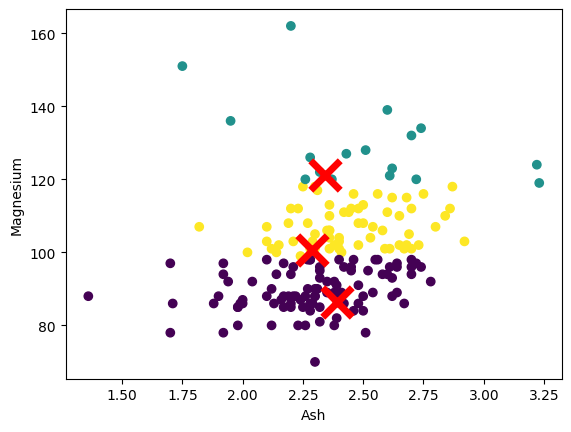

In [ ]:
xs = df['Ash']
ys = df['Magnesium']

labels = Clusters
centroids = kmn.cluster_centers_ # this is very important function to see the place of center from clustering
plt.scatter(xs, ys, c=labels)
plt.xlabel('Ash')
plt.ylabel('Magnesium')
plt.scatter(centroids[:,0],centroids[:,3],marker='x', linewidth=5, s=450,c='red')
plt.show()

In [ ]:
centroids

array([[  2.39046154,   2.24353846,  12.66984615,  86.35384615,
          1.78430769],
       [  2.3427027 ,   2.50135135,  13.33945946, 121.18918919,
          2.35027027],
       [  2.28697368,   2.40605263,  13.11855263, 100.75      ,
          2.0825    ]])

** best number for K **

In [ ]:
np.arange(1,19)

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18])

In [ ]:
kmn.inertia_

7863.761312927565

In [ ]:
inertia_list = []
for k in np.arange(1,19): # the structure of loop should be consistent and the next lines should be after for .
    kmn =KMeans(n_clusters = k)
    kmn.fit(df2)# only add your data here the rest codes are the same for your dataset
    inertia_list.append(kmn.inertia_)# make a list which we add the caluculation of inertial in each loop to this list
inertia_list # this line is out of the loop and we undestood the loop ended here.


[36633.58316348316,
 14021.71696006571,
 7599.611851732501,
 4566.828330902261,
 3371.4433863232343,
 2692.225611551954,
 2042.9903362118755,
 1488.0740280638947,
 1332.0839423291388,
 1126.6771855905952,
 1050.4068920439645,
 1012.2371277420759,
 806.691834451752,
 758.6026086898581,
 753.599005813492,
 664.1465559461071,
 717.0062738090218,
 641.6737159686152]

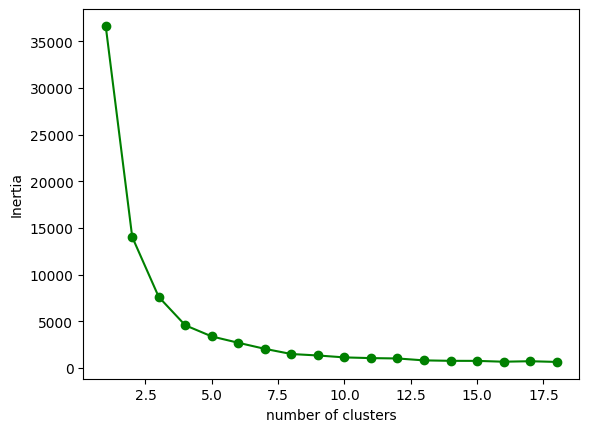

In [ ]:
plt.plot(np.arange(1,19),inertia_list,'o-',c='green')
plt.xlabel('number of clusters')
plt.ylabel('Inertia')
plt.show()